# LDPC BLER Performance Analysis

This notebook reads `out/cuda_ldpc_decoder_result_bg1.pkl`, converts the saved simulation data into a pandas DataFrame, filters to `algo = 0`, and plots BLER versus SNR grouped by `Qm` with seaborn.

In [2]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")

In [3]:
#filename = "cuda_ldpc_decoder_result_bg1.pkl"
filename = "c_ldpc_decoder_result_bg1.pkl"

In [4]:
result_paths = [
    Path("out") / filename,
    Path("../out") / filename,
]
result_path = next((path for path in result_paths if path.exists()), None)
if result_path is None:
    raise FileNotFoundError(f"Cannot find {filename}")

with result_path.open("rb") as f:
    test_result, decoder_config_list, snr_power_db_list, test_num = pickle.load(f)

print(f"Loaded result file: {result_path}")
print(f"LDPC configurations: {len(test_result)}")
print(f"Decoder configurations: {len(decoder_config_list)}")
print(f"SNR points: {len(snr_power_db_list)}")
print(f"Trials per SNR point: {test_num}")

Loaded result file: ../out/c_ldpc_decoder_result_bg1.pkl
LDPC configurations: 5
Decoder configurations: 5
SNR points: 33
Trials per SNR point: 2000


In [5]:
DECODER_LABELS = {
    0: "Floating-point BP",
    1: "Fixed-point min-sum",
    2: "Trained-table min-sum",
    3: "Degree-dependent min-sum",
    4: "Floating-point min-sum",
}


def format_coderate(coderate):
    for denominator in range(1, 1001):
        numerator = round(coderate * denominator)
        if abs(coderate - numerator / denominator) < 1e-12:
            return f"{numerator}/{denominator}"
    return f"{coderate:.4g}"


rows = []
for config_tuple, bler_list, ber_list in test_result:
    Qm, rv, B, coderate, bgn, crctype = config_tuple
    config_label = (
        f"Qm={Qm}, rv={rv}, B={B}, "
        f"R={format_coderate(coderate)}, BG{bgn}, CRC={crctype}"
    )

    for snr_db, bler_values, ber_values in zip(
        snr_power_db_list, bler_list, ber_list
    ):
        for decoder_idx, decoder_config in enumerate(decoder_config_list):
            algo = decoder_config[0]
            # run_bler_sweep() already folds Qm into noise_power_db, so
            # snr_db is coded-bit Ec/N0. Convert to information-bit Eb/N0
            # by accounting for code rate only.
            ebn0_db = float(snr_db) - 10 * np.log10(coderate)
            rows.append(
                {
                    "snr_db": float(snr_db),
                    "ebn0_db": ebn0_db,
                    "bler": float(bler_values[decoder_idx]),
                    "ber": float(ber_values[decoder_idx]),
                    "decoder": DECODER_LABELS.get(algo, f"algo {algo}"),
                    "algo": algo,
                    "Qm": Qm,
                    "rv": rv,
                    "B": B,
                    "coderate": coderate,
                    "bgn": bgn,
                    "crctype": crctype,
                    "config": config_label,
                }
            )

df = pd.DataFrame(rows)
df.head()

,snr_db,ebn0_db,bler,ber,decoder,algo,Qm,rv,B,coderate,bgn,crctype,config
0,-5.0,-0.228787,0.8435,0.112084,Floating-point BP,0,1,0,3840,0.333333,1,0,"Qm=1, rv=0, B=3840, R=1/3, BG1, CRC=0"
1,-5.0,-0.228787,0.9990,0.238362,Fixed-point min-sum,1,1,0,3840,0.333333,1,0,"Qm=1, rv=0, B=3840, R=1/3, BG1, CRC=0"
2,-5.0,-0.228787,1.0000,0.250921,Trained-table min-sum,2,1,0,3840,0.333333,1,0,"Qm=1, rv=0, B=3840, R=1/3, BG1, CRC=0"
3,-5.0,-0.228787,1.0000,0.250921,Degree-dependent min-sum,3,1,0,3840,0.333333,1,0,"Qm=1, rv=0, B=3840, R=1/3, BG1, CRC=0"
4,-5.0,-0.228787,1.0000,0.238696,Floating-point min-sum,4,1,0,3840,0.333333,1,0,"Qm=1, rv=0, B=3840, R=1/3, BG1, CRC=0"


In [6]:
algo0_df = df[df["algo"] == 0].copy() #choos c_lib floating BP

algo0_df.groupby("Qm", as_index=False).agg(
    min_bler=("bler", "min"),
    max_bler=("bler", "max"),
    snr_points=("snr_db", "count"),
)

,Qm,min_bler,max_bler,snr_points
0,1,0.0000,0.8435,33
1,2,0.0000,0.8580,33
2,4,0.0000,1.0000,33
3,6,0.0000,1.0000,33
4,8,0.0005,1.0000,33


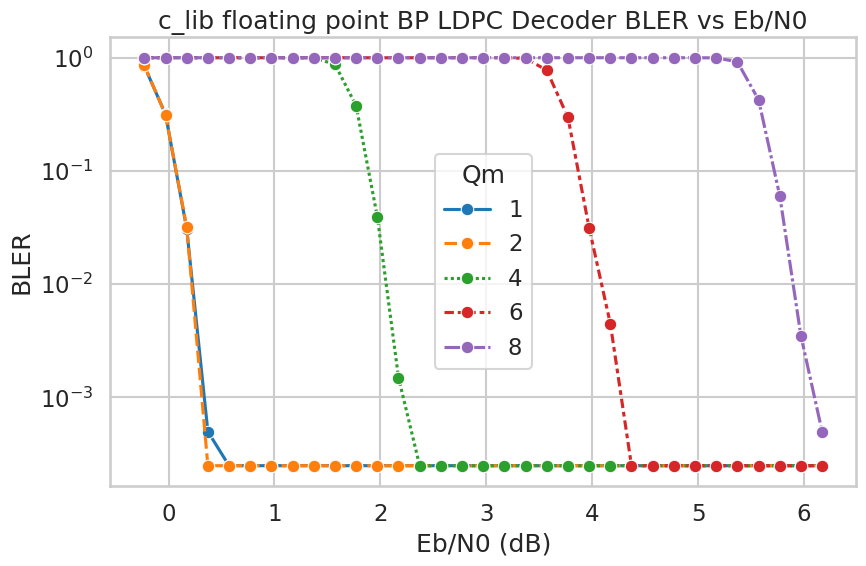

In [7]:
plot_df = algo0_df.copy()

# A log y-axis cannot display exact zero. Replace zero-BLER points with a
# plotting floor below the resolution of the Monte Carlo run.
bler_floor = 0.5 / test_num
plot_df["bler_for_plot"] = plot_df["bler"].clip(lower=bler_floor)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(
    data=plot_df,
    #x="snr_db",
    x="ebn0_db",
    y="bler_for_plot",
    hue="Qm",
    style="Qm",
    marker="o",
    palette="tab10",
    ax=ax,
)

ax.set_yscale("log")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("BLER")
ax.grid(True)
ax.minorticks_on()
#ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.7)
#ax.grid(True, which="minor", axis="both", linestyle=":", linewidth=0.4, alpha=0.8)
ax.set_title("c_lib floating point BP LDPC Decoder BLER vs Eb/N0")
sns.move_legend(ax, "best", title="Qm")
fig.tight_layout()

plt.show()

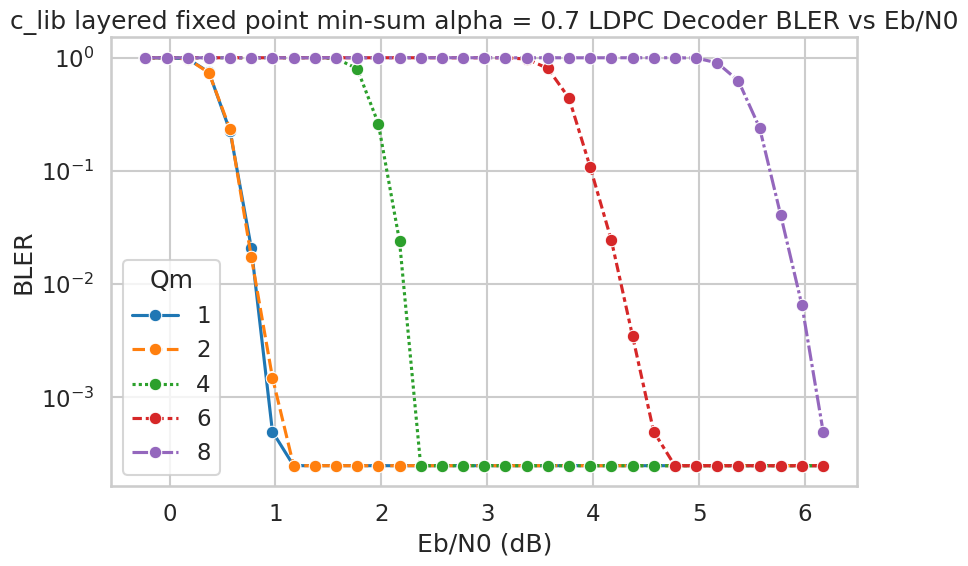

In [8]:
plot_df = df[df["algo"] == 1].copy() #c_lib normalized min-sum

# A log y-axis cannot display exact zero. Replace zero-BLER points with a
# plotting floor below the resolution of the Monte Carlo run.
bler_floor = 0.5 / test_num
plot_df["bler_for_plot"] = plot_df["bler"].clip(lower=bler_floor)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(
    data=plot_df,
    #x="snr_db",
    x="ebn0_db",
    y="bler_for_plot",
    hue="Qm",
    style="Qm",
    marker="o",
    palette="tab10",
    ax=ax,
)

ax.set_yscale("log")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("BLER")
ax.grid(True)
ax.minorticks_on()
ax.set_title("c_lib layered fixed point min-sum alpha = 0.7 LDPC Decoder BLER vs Eb/N0")
sns.move_legend(ax, "best", title="Qm")
fig.tight_layout()
plt.show()